Лабораторна робота 2. Лавренюк ФІТ 4-10

---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"

tables = pd.read_html(
    url,
    storage_options={
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0 Safari/537.36"
    }
)

# Знаходимо таблицю, яка містить дані про IMF
df = None

for table in tables:
    columns_text = " ".join(str(col) for col in table.columns)

    if "IMF" in columns_text and "World Bank" in columns_text:
        df = table.copy()
        break

if df is None:
    raise ValueError("Не вдалося знайти потрібну таблицю на Wikipedia.")

# Якщо назви стовпців багаторівневі — об'єднуємо їх
if isinstance(df.columns, pd.MultiIndex):
    new_columns = []

    for col in df.columns:
        parts = [str(x) for x in col if str(x) != "nan"]
        new_columns.append(" ".join(parts))

    df.columns = new_columns

print("Назви стовпців:")
print(df.columns.tolist())

Назви стовпців:
['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


1. Вивести перші 5 рядків датасета

In [2]:
print("Перші 5 рядків датасета:")
display(df.head())

Перші 5 рядків датасета:


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [3]:
print("Розмір датасета:")
print(df.shape)

print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Розмір датасета:
(222, 4)
Кількість рядків: 222
Кількість стовпців: 4


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [4]:
print("Початкові стовпці:")
print(df.columns.tolist())

# Виводимо перші рядки, щоб побачити структуру таблиці
display(df.head())

Початкові стовпці:
['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


In [5]:
# Автоматично знаходимо потрібні стовпці

country_col = None
imf_col = None
world_bank_col = None
un_col = None

for col in df.columns:
    col_str = str(col).lower()

    if country_col is None and ("country" in col_str or "economy" in col_str):
        country_col = col

    if imf_col is None and "imf" in col_str:
        imf_col = col

    if world_bank_col is None and "world bank" in col_str:
        world_bank_col = col

    if un_col is None and ("united nations" in col_str or col_str.startswith("un")):
        un_col = col

print("Країна:", country_col)
print("IMF:", imf_col)
print("World Bank:", world_bank_col)
print("United Nations:", un_col)

Країна: Country/Territory
IMF: IMF (2026)[1]
World Bank: World Bank (2025)[6]
United Nations: United Nations (2024)[7]


In [6]:
# Залишаємо тільки необхідні стовпці

df = df[[country_col, imf_col, world_bank_col, un_col]].copy()

# Надаємо зрозумілі назви
df.columns = [
    "Country",
    "IMF (2026)",
    "World Bank (2025)",
    "United Nations (2024)"
]

print("Стовпці після оптимізації:")
print(df.columns.tolist())

display(df.head())

Стовпці після оптимізації:
['Country', 'IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [7]:
import numpy as np

# Замінюємо різні варіанти тире на NaN
df = df.replace(["—", "–", "-", "— "], np.nan)

# Перетворюємо числові стовпці на числовий тип
numeric_columns = [
    "IMF (2026)",
    "World Bank (2025)",
    "United Nations (2024)"
]

for column in numeric_columns:
    df[column] = (
        df[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace(r"\[.*?\]", "", regex=True)
        .str.strip()
    )

    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Кількість пропущених значень до заповнення:")
print(df.isna().sum())

Кількість пропущених значень до заповнення:
Country                   0
IMF (2026)               31
World Bank (2025)        35
United Nations (2024)     9
dtype: int64


In [8]:
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].mean())

print("Кількість пропущених значень після заповнення:")
print(df.isna().sum())

Кількість пропущених значень після заповнення:
Country                  0
IMF (2026)               0
World Bank (2025)        0
United Nations (2024)    0
dtype: int64


5. Ще раз вивести датасет

In [9]:
print("Датасет після обробки:")
display(df)

Датасет після обробки:


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,World,1.262953e+08,1.183502e+08,111565144.0
1,United States,3.238392e+07,3.076970e+07,29298000.0
2,China[n 1],2.085159e+07,1.949804e+07,18743802.0
3,Germany,5.452858e+06,5.050923e+06,4659929.0
4,Japan,4.379253e+06,4.435163e+06,4026211.0
...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
219,Nauru,1.960000e+02,1.760000e+02,187.0
220,Montserrat,1.319229e+06,1.255590e+06,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [10]:
print("Кількість дублікатів:")
print(df.duplicated().sum())

Кількість дублікатів:
0


In [11]:
df = df.drop_duplicates().reset_index(drop=True)

print("Кількість дублікатів після видалення:")
print(df.duplicated().sum())

print("Новий розмір датасета:")
print(df.shape)

Кількість дублікатів після видалення:
0
Новий розмір датасета:
(222, 4)


7.	Вивести описову статистику датасету describe()

In [12]:
print("Описова статистика:")
display(df[numeric_columns].describe())

Описова статистика:


,IMF (2026),World Bank (2025),United Nations (2024)
count,2.220000e+02,2.220000e+02,2.220000e+02
mean,1.319229e+06,1.255590e+06,1.043818e+06
std,8.838876e+06,8.288461e+06,7.830341e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.932375e+04,2.003400e+04,9.170750e+03
50%,1.039745e+05,9.986350e+04,4.322450e+04
75%,7.726678e+05,1.041520e+06,3.048545e+05
max,1.262953e+08,1.183502e+08,1.115651e+08


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [13]:
df["Difference IMF-WB"] = (
    df["IMF (2026)"] - df["World Bank (2025)"]
)

df["Absolute Difference IMF-WB"] = (
    df["Difference IMF-WB"].abs()
)

print("Різниця між IMF (2026) та World Bank (2025):")

display(
    df[
        [
            "Country",
            "IMF (2026)",
            "World Bank (2025)",
            "Difference IMF-WB",
            "Absolute Difference IMF-WB"
        ]
    ].sort_values(
        "Absolute Difference IMF-WB",
        ascending=False
    )
)

Різниця між IMF (2026) та World Bank (2025):


,Country,IMF (2026),World Bank (2025),Difference IMF-WB,Absolute Difference IMF-WB
0,World,1.262953e+08,118350166.0,7.945165e+06,7.945165e+06
1,United States,3.238392e+07,30769700.0,1.614220e+06,1.614220e+06
2,China[n 1],2.085159e+07,19498039.0,1.353554e+06,1.353554e+06
197,Sint Maarten,1.319229e+06,1888.0,1.317341e+06,1.317341e+06
146,Palestine[n 11][n 12],1.319229e+06,17167.0,1.302062e+06,1.302062e+06
...,...,...,...,...,...
219,Nauru,1.960000e+02,176.0,2.000000e+01,2.000000e+01
213,Federated States of Micronesia,5.210000e+02,502.0,1.900000e+01,1.900000e+01
205,Saint Vincent and the Grenadines,1.236000e+03,1255.0,-1.900000e+01,1.900000e+01
221,Tuvalu,6.500000e+01,57.0,8.000000e+00,8.000000e+00


In [14]:
top_difference = df.sort_values(
    "Absolute Difference IMF-WB",
    ascending=False
).head(10)

print("10 країн з найбільшою різницею між IMF та World Bank:")

display(
    top_difference[
        [
            "Country",
            "IMF (2026)",
            "World Bank (2025)",
            "Difference IMF-WB",
            "Absolute Difference IMF-WB"
        ]
    ]
)

10 країн з найбільшою різницею між IMF та World Bank:


,Country,IMF (2026),World Bank (2025),Difference IMF-WB,Absolute Difference IMF-WB
0,World,1.262953e+08,1.183502e+08,7.945165e+06,7.945165e+06
1,United States,3.238392e+07,3.076970e+07,1.614220e+06,1.614220e+06
2,China[n 1],2.085159e+07,1.949804e+07,1.353554e+06,1.353554e+06
197,Sint Maarten,1.319229e+06,1.888000e+03,1.317341e+06,1.317341e+06
146,Palestine[n 11][n 12],1.319229e+06,1.716700e+04,1.302062e+06,1.302062e+06
192,San Marino,2.417000e+03,1.255590e+06,-1.253173e+06,1.253173e+06
179,Aruba,4.671000e+03,1.255590e+06,-1.250919e+06,1.250919e+06
172,South Sudan,6.069000e+03,1.255590e+06,-1.249521e+06,1.249521e+06
168,Yemen,7.435000e+03,1.255590e+06,-1.248155e+06,1.248155e+06
159,Liechtenstein,9.442000e+03,1.255590e+06,-1.246148e+06,1.246148e+06


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [15]:
correlation = df[
    [
        "IMF (2026)",
        "World Bank (2025)",
        "United Nations (2024)"
    ]
].corr()

print("Матриця кореляції:")
display(correlation)

Матриця кореляції:


,IMF (2026),World Bank (2025),United Nations (2024)
IMF (2026),1.000000,0.999497,0.998998
World Bank (2025),0.999497,1.000000,0.998864
United Nations (2024),0.998998,0.998864,1.000000


In [16]:
corr_pairs = []

columns = [
    "IMF (2026)",
    "World Bank (2025)",
    "United Nations (2024)"
]

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        corr_value = correlation.loc[columns[i], columns[j]]

        corr_pairs.append(
            (columns[i], columns[j], corr_value, abs(corr_value))
        )

corr_pairs = sorted(
    corr_pairs,
    key=lambda x: x[3],
    reverse=True
)

print("Пари змінних за силою кореляції:")

for pair in corr_pairs:
    print(
        f"{pair[0]} — {pair[1]}: "
        f"{pair[2]:.4f}"
    )

print("\nНайвища кореляція:")
print(
    f"{corr_pairs[0][0]} — {corr_pairs[0][1]}: "
    f"{corr_pairs[0][2]:.4f}"
)

Пари змінних за силою кореляції:
IMF (2026) — World Bank (2025): 0.9995
IMF (2026) — United Nations (2024): 0.9990
World Bank (2025) — United Nations (2024): 0.9989

Найвища кореляція:
IMF (2026) — World Bank (2025): 0.9995


10. Обчислити середнє значення за стовпцями

In [17]:
print("Середнє значення за стовпцями:")

means = df[
    [
        "IMF (2026)",
        "World Bank (2025)",
        "United Nations (2024)"
    ]
].mean()

display(means)

Середнє значення за стовпцями:


,0
IMF (2026),1.319229e+06
World Bank (2025),1.255590e+06
United Nations (2024),1.043818e+06


In [18]:
for column in numeric_columns:
    print(f"{column}: {df[column].mean():,.2f}")

IMF (2026): 1,319,229.25
World Bank (2025): 1,255,590.42
United Nations (2024): 1,043,818.22


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [19]:
df["Standard Deviation"] = df[
    [
        "IMF (2026)",
        "World Bank (2025)",
        "United Nations (2024)"
    ]
].std(axis=1)

print("Стандартне відхилення для кожної країни:")

display(
    df[
        [
            "Country",
            "IMF (2026)",
            "World Bank (2025)",
            "United Nations (2024)",
            "Standard Deviation"
        ]
    ].sort_values(
        "Standard Deviation",
        ascending=False
    )
)

Стандартне відхилення для кожної країни:


,Country,IMF (2026),World Bank (2025),United Nations (2024),Standard Deviation
0,World,1.262953e+08,118350166.0,111565144.0,7.372704e+06
1,United States,3.238392e+07,30769700.0,29298000.0,1.543508e+06
2,China[n 1],2.085159e+07,19498039.0,18743802.0,1.068002e+06
197,Sint Maarten,1.319229e+06,1888.0,1670.0,7.606303e+05
146,Palestine[n 11][n 12],1.319229e+06,17167.0,16017.0,7.520782e+05
...,...,...,...,...,...
207,Saint Kitts and Nevis,1.143000e+03,1184.0,1122.0,3.153305e+01
218,Marshall Islands,3.420000e+02,308.0,281.0,3.056687e+01
213,Federated States of Micronesia,5.210000e+02,502.0,471.0,2.523886e+01
219,Nauru,1.960000e+02,176.0,187.0,1.001665e+01


In [20]:
max_std = df.loc[df["Standard Deviation"].idxmax()]

print("Країна з найвищою варіативністю:")

print("Країна:", max_std["Country"])
print("Стандартне відхилення:", max_std["Standard Deviation"])

Країна з найвищою варіативністю:
Країна: World
Стандартне відхилення: 7372703.930407509


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [21]:
for column in numeric_columns:

    max_index = df[column].idxmax()
    min_index = df[column].idxmin()

    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)

    print(
        "Найвищий показник:",
        df.loc[max_index, "Country"],
        "-",
        df.loc[max_index, column]
    )

    print(
        "Найнижчий показник:",
        df.loc[min_index, "Country"],
        "-",
        df.loc[min_index, column]
    )


IMF (2026)
Найвищий показник: World - 126295331.0
Найнижчий показник: Tuvalu - 65.0

World Bank (2025)
Найвищий показник: World - 118350166.0
Найнижчий показник: Tuvalu - 57.0

United Nations (2024)
Найвищий показник: World - 111565144.0
Найнижчий показник: Tuvalu - 56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

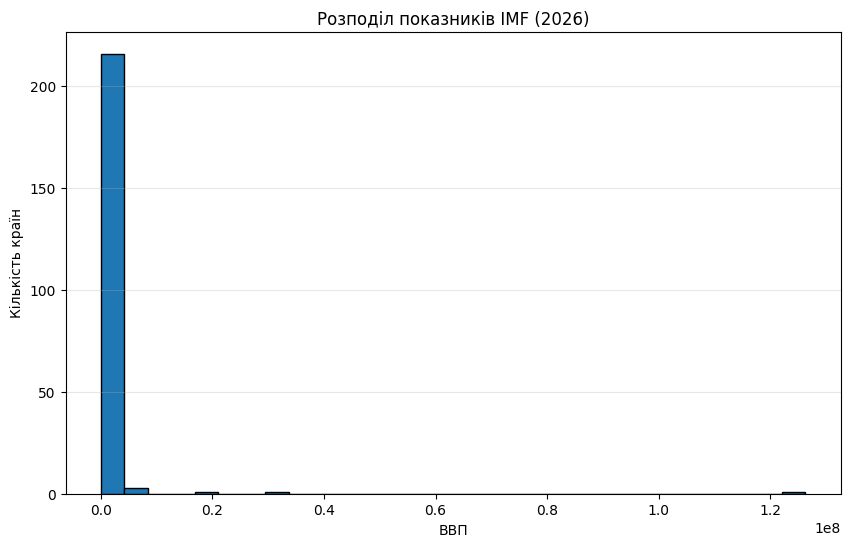

In [22]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["IMF (2026)"],
    bins=30,
    edgecolor="black"
)

plt.title("Розподіл показників IMF (2026)")
plt.xlabel("ВВП")
plt.ylabel("Кількість країн")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [23]:
q1 = df["IMF (2026)"].quantile(0.25)
q3 = df["IMF (2026)"].quantile(0.75)

iqr = q3 - q1

upper_limit = q3 + 1.5 * iqr

outliers = df[df["IMF (2026)"] > upper_limit]

print("Країни, показники яких можуть виділятися як дуже великі:")

display(
    outliers[
        ["Country", "IMF (2026)"]
    ].sort_values(
        "IMF (2026)",
        ascending=False
    )
)

Країни, показники яких можуть виділятися як дуже великі:


,Country,IMF (2026)
0,World,126295331.0
1,United States,32383920.0
2,China[n 1],20851593.0
3,Germany,5452858.0
4,Japan,4379253.0
5,United Kingdom,4264794.0
6,India,4153191.0
7,France,3596094.0
8,Italy,2738164.0
9,Russia,2656452.0


14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [24]:
for column in numeric_columns:
    share_column = column + " Share"

    df[share_column] = (
        df[column] / df[column].sum() * 100
    )

print("Частка кожної країни у загальному значенні:")

display(
    df[
        [
            "Country",
            "IMF (2026) Share",
            "World Bank (2025) Share",
            "United Nations (2024) Share"
        ]
    ]
)

Частка кожної країни у загальному значенні:


,Country,IMF (2026) Share,World Bank (2025) Share,United Nations (2024) Share
0,World,43.123505,42.458818,48.144944
1,United States,11.057480,11.038811,12.643291
2,China[n 1],7.119770,6.995036,8.088721
3,Germany,1.861877,1.812048,2.010951
4,Japan,1.495295,1.591141,1.737475
...,...,...,...,...
217,Palau,0.000129,0.000124,0.000134
218,Marshall Islands,0.000117,0.000110,0.000121
219,Nauru,0.000067,0.000063,0.000081
220,Montserrat,0.450450,0.450450,0.000035


In [25]:
for column in numeric_columns:

    share_column = column + " Share"

    print("\n" + column)

    display(
        df[
            ["Country", share_column]
        ]
        .sort_values(
            share_column,
            ascending=False
        )
        .head(10)
    )


IMF (2026)


,Country,IMF (2026) Share
0,World,43.123505
1,United States,11.057480
2,China[n 1],7.119770
3,Germany,1.861877
4,Japan,1.495295
5,United Kingdom,1.456213
6,India,1.418106
7,France,1.227885
8,Italy,0.934945
9,Russia,0.907045



World Bank (2025)


,Country,World Bank (2025) Share
0,World,42.458818
1,United States,11.038811
2,China[n 1],6.995036
3,Germany,1.812048
4,Japan,1.591141
5,United Kingdom,1.435952
6,India,1.419262
7,France,1.207686
9,Russia,0.918885
8,Italy,0.915386



United Nations (2024)


,Country,United Nations (2024) Share
0,World,48.144944
1,United States,12.643291
2,China[n 1],8.088721
3,Germany,2.010951
4,Japan,1.737475
6,India,1.705556
5,United Kingdom,1.590609
7,France,1.363861
8,Italy,1.027424
11,Canada,0.979631


In [26]:
print("Перевірка суми часток:")

for column in numeric_columns:
    share_column = column + " Share"
    print(
        column,
        ":",
        df[share_column].sum()
    )

Перевірка суми часток:
IMF (2026) : 99.99999999999997
World Bank (2025) : 99.99999999999999
United Nations (2024) : 100.0


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

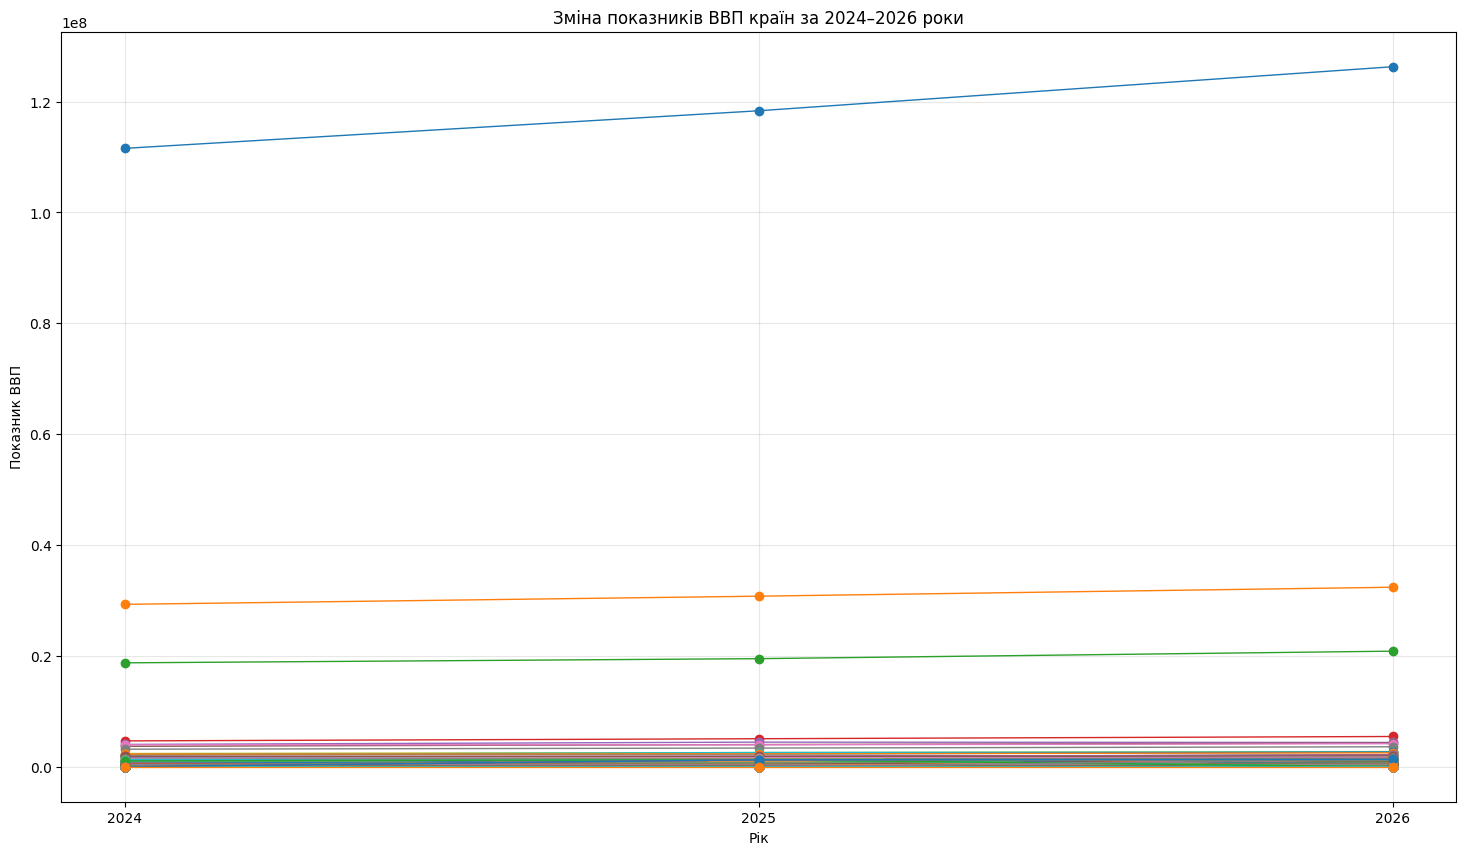

In [27]:
years = [
    "United Nations (2024)",
    "World Bank (2025)",
    "IMF (2026)"
]

plt.figure(figsize=(18, 10))

for index, row in df.iterrows():
    plt.plot(
        [2024, 2025, 2026],
        [
            row["United Nations (2024)"],
            row["World Bank (2025)"],
            row["IMF (2026)"]
        ],
        marker="o",
        linewidth=1
    )

plt.title("Зміна показників ВВП країн за 2024–2026 роки")
plt.xlabel("Рік")
plt.ylabel("Показник ВВП")

plt.xticks([2024, 2025, 2026])

plt.grid(True, alpha=0.3)

plt.show()

In [28]:
stable_growth = df[
    (df["United Nations (2024)"] <
     df["World Bank (2025)"]) &

    (df["World Bank (2025)"] <
     df["IMF (2026)"])
]

print("Країни зі стабільним зростанням:")

display(
    stable_growth[
        [
            "Country",
            "United Nations (2024)",
            "World Bank (2025)",
            "IMF (2026)"
        ]
    ]
)

Країни зі стабільним зростанням:


,Country,United Nations (2024),World Bank (2025),IMF (2026)
0,World,111565144.0,1.183502e+08,1.262953e+08
1,United States,29298000.0,3.076970e+07,3.238392e+07
2,China[n 1],18743802.0,1.949804e+07,2.085159e+07
3,Germany,4659929.0,5.050923e+06,5.452858e+06
5,United Kingdom,3685881.0,4.002588e+06,4.264794e+06
...,...,...,...,...
216,Kiribati,343.0,3.490000e+02,4.010000e+02
217,Palau,310.0,3.450000e+02,3.770000e+02
218,Marshall Islands,281.0,3.080000e+02,3.420000e+02
220,Montserrat,81.0,1.255590e+06,1.319229e+06


In [29]:
stable_decline = df[
    (df["United Nations (2024)"] >
     df["World Bank (2025)"]) &

    (df["World Bank (2025)"] >
     df["IMF (2026)"])
]

print("Країни зі стабільним спадом:")

display(
    stable_decline[
        [
            "Country",
            "United Nations (2024)",
            "World Bank (2025)",
            "IMF (2026)"
        ]
    ]
)

Країни зі стабільним спадом:


,Country,United Nations (2024),World Bank (2025),IMF (2026)
53,Iran,448092.0,362682.0,300293.0
72,Ethiopia,142275.0,126359.0,121527.0


In [30]:
print(
    "Кількість країн зі стабільним зростанням:",
    len(stable_growth)
)

print(
    "Кількість країн зі стабільним спадом:",
    len(stable_decline)
)

Кількість країн зі стабільним зростанням: 188
Кількість країн зі стабільним спадом: 2
